# Ensambles de modelos

## Objetivo y relación con el proyecto

Un **ensamble** combina varios modelos para que, en conjunto, predigan mejor que cada uno por separado, de manera similar a consultar la opinión de varios especialistas en lugar de la de uno solo. Existen dos familias:

- **Ensambles homogéneos:** muchos modelos del *mismo* tipo (por ejemplo, árboles de decisión) entrenados sobre variantes de los datos (*bagging*) o en secuencia, corrigiendo cada uno los errores del anterior (*boosting*).
- **Ensambles heterogéneos:** modelos de tipos *distintos* cuyas predicciones se combinan por promedio (*voting*) o mediante un modelo final que aprende a combinarlas (*stacking* y *blending*).

El producto del proyecto es un detector de objetos basado en imágenes (Faster R-CNN, documentado en `05_Modelo_Final.ipynb`). En ese detector la unidad que se combinaría son cajas con puntuación y no valores numéricos, por lo que un ensamble clásico no aplica sin una adaptación considerable (ver la sección "Naturaleza de implementación" de esa libreta).

Esta libreta aplica las estrategias de ensamble a los **modelos tabulares de la fase anterior** (`04_Modelos.ipynb`), que predicen el tamaño relativo de un objeto a partir de las mediciones de la cabeza y la hora de captura. Se utilizan por tres razones: son los modelos individuales que ya existen en el proyecto, son rápidos de entrenar y permiten comparar con rigor las estrategias de ensamble que pide la actividad. Su resultado debe leerse como un **experimento preliminar de relación geométrica**, no como una medida de cumplimiento del estándar de vestimenta.

## Preparación del conjunto

Se reproduce la preparación de datos de la fase 04 para que los resultados sean comparables: cada objeto anotado se asocia con la cabeza más cercana de su imagen, el objetivo es `log_area_rel` (logaritmo del área relativa de la caja) y las entradas son únicamente mediciones de la cabeza y la hora. La separación entrenamiento/prueba y la validación cruzada se hacen **agrupadas por imagen**, de modo que los objetos de una misma fotografía nunca queden en conjuntos distintos.

In [1]:
import os
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (BaggingRegressor, GradientBoostingRegressor, RandomForestRegressor,
                              StackingRegressor, VotingRegressor)
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import BayesianRidge, GammaRegressor, LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GroupKFold, GroupShuffleSplit, RandomizedSearchCV,
                                     cross_val_predict, cross_validate)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.25

annotations = pd.read_csv("../DataCapture/anotaciones_baseline.csv")
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")

for tabla in (annotations, heads):
    tabla["imagen"] = tabla["imagen"].astype(str).map(lambda v: Path(v).name)
    for col in ["x", "y", "w", "h"]:
        tabla[col] = pd.to_numeric(tabla[col], errors="coerce")

annotations = annotations.dropna(subset=["imagen", "x", "y", "w", "h", "image_width", "image_height"])
annotations = annotations[(annotations["w"] > 0) & (annotations["h"] > 0)].reset_index(drop=True)
heads = heads.dropna(subset=["imagen", "x", "y", "w", "h"])
heads = heads[(heads["w"] > 0) & (heads["h"] > 0)]
heads = heads[["imagen", "x", "y", "w", "h"]].rename(
    columns={"x": "head_x", "y": "head_y", "w": "head_w", "h": "head_h"})
heads["head_cx"] = heads["head_x"] + heads["head_w"] / 2
heads["head_cy"] = heads["head_y"] + heads["head_h"] / 2

annotations["_object_id"] = np.arange(len(annotations))
annotations["obj_cx"] = annotations["x"] + annotations["w"] / 2
annotations["obj_cy"] = annotations["y"] + annotations["h"] / 2

# Asociación objeto-cabeza: cabeza más cercana dentro de la misma imagen
pares = annotations[["_object_id", "imagen", "obj_cx", "obj_cy"]].merge(heads, on="imagen", how="inner")
pares["distancia"] = np.hypot(pares["obj_cx"] - pares["head_cx"], pares["obj_cy"] - pares["head_cy"])
cercanas = pares.loc[pares.groupby("_object_id")["distancia"].idxmin(),
                     ["_object_id", "head_x", "head_y", "head_w", "head_h", "head_cx", "head_cy"]]
df = annotations.merge(cercanas, on="_object_id", how="inner")

df["hora"] = df["imagen"].str.extract(r"_(\d{2})\d{4}_", expand=False).astype(int)
df["area_rel"] = (df["w"] * df["h"]) / (df["image_width"] * df["image_height"])
df["log_area_rel"] = np.log1p(df["area_rel"] * 1000)
df["head_area_rel"] = (df["head_w"] * df["head_h"]) / (df["image_width"] * df["image_height"])
df["log_head_area_rel"] = np.log1p(df["head_area_rel"] * 1000)
df["head_cx_rel"] = df["head_cx"] / df["image_width"]
df["head_cy_rel"] = df["head_cy"] / df["image_height"]

FEATURES = ["log_head_area_rel", "head_w", "head_h", "head_cx_rel", "head_cy_rel", "hora"]
TARGET = "log_area_rel"

df_model = df.dropna(subset=FEATURES + [TARGET]).copy()
X, y, GRUPOS = df_model[FEATURES], df_model[TARGET], df_model["imagen"]

splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=GRUPOS))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = GRUPOS.iloc[train_idx]
assert set(g_train).isdisjoint(set(GRUPOS.iloc[test_idx]))

cv = GroupKFold(n_splits=5)
print(f"Observaciones: {len(df_model)} | Imágenes: {GRUPOS.nunique()}")
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")

Observaciones: 72 | Imágenes: 41
Entrenamiento: (52, 6) | Prueba: (20, 6)


## Modelos individuales de la fase 04

Se reconstruyen los ocho modelos individuales de `04_Modelos.ipynb` con la misma configuración (el modelo ingenuo, que predice la media, sirve como desempeño mínimo). Para Random Forest y MLP se repite la **búsqueda aleatoria de hiperparámetros** con validación cruzada agrupada y la métrica MAE, con las mismas semillas y rejillas, y se registra el tiempo de búsqueda.

In [2]:
def construir_modelos():
    return {
        "Ingenuo (media)": DummyRegressor(strategy="mean"),
        "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
        "Gamma Regression": make_pipeline(StandardScaler(), GammaRegressor()),
        "Bayesian Ridge": make_pipeline(StandardScaler(), BayesianRidge()),
        "SGDRegressor": make_pipeline(StandardScaler(), SGDRegressor(random_state=RANDOM_STATE)),
        "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
        "Red neuronal (MLP)": make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(8,), solver="lbfgs", alpha=1.0, max_iter=2000, random_state=RANDOM_STATE)),
    }

def buscar(estimador, parametros, n_iter):
    busqueda = RandomizedSearchCV(estimador, parametros, n_iter=n_iter, scoring="neg_mean_absolute_error",
                                  cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    t0 = time.perf_counter()
    busqueda.fit(X_train, y_train, groups=g_train)
    return busqueda, time.perf_counter() - t0

busqueda_rf, t_rf = buscar(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    {"n_estimators": [100, 300, 500], "max_depth": [None, 3, 5, 8], "min_samples_split": [2, 5, 10],
     "min_samples_leaf": [1, 2, 4], "max_features": [1.0, 0.7, "sqrt"]}, n_iter=25)

busqueda_mlp, t_mlp = buscar(
    make_pipeline(StandardScaler(), MLPRegressor(solver="lbfgs", max_iter=3000, random_state=RANDOM_STATE)),
    {"mlpregressor__hidden_layer_sizes": [(4,), (8,), (16,), (8, 4), (16, 8)],
     "mlpregressor__alpha": [0.001, 0.01, 0.1, 1.0], "mlpregressor__activation": ["relu", "tanh"]}, n_iter=20)

print("Random Forest ajustado:", busqueda_rf.best_params_, f"| búsqueda: {t_rf:.1f} s")
print("MLP ajustado:", busqueda_mlp.best_params_, f"| búsqueda: {t_mlp:.1f} s")

Random Forest ajustado: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 3} | búsqueda: 9.3 s
MLP ajustado: {'mlpregressor__hidden_layer_sizes': (16, 8), 'mlpregressor__alpha': 1.0, 'mlpregressor__activation': 'relu'} | búsqueda: 1.5 s


## Ensambles homogéneos

- **Bagging:** 200 árboles poco profundos (profundidad 3, mínimo 3 observaciones por hoja), cada uno entrenado con una muestra con reemplazo de los datos. Al promediar se reduce la varianza de un árbol individual. Se limita la profundidad porque el conjunto es pequeño y los árboles profundos memorizarían.
- **Random Forest ajustado:** variante de bagging que, además, sortea las variables en cada división. Es el modelo ajustado en la sección anterior.
- **Gradient Boosting:** árboles pequeños entrenados en secuencia, cada uno sobre el error del anterior. Su configuración (número de árboles, tasa de aprendizaje, profundidad, submuestreo y función de pérdida) se optimiza con búsqueda aleatoria y validación cruzada agrupada, igual que los modelos de la fase anterior.

In [3]:
bagging = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=3, min_samples_leaf=3, random_state=RANDOM_STATE),
    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)

busqueda_gb, t_gb = buscar(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    {"n_estimators": [50, 100, 200], "learning_rate": [0.01, 0.03, 0.1], "max_depth": [1, 2, 3],
     "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [2, 4], "loss": ["squared_error", "absolute_error", "huber"]},
    n_iter=25)
print("Gradient Boosting ajustado:", busqueda_gb.best_params_, f"| búsqueda: {t_gb:.1f} s")

Gradient Boosting ajustado: {'subsample': 0.6, 'n_estimators': 200, 'min_samples_leaf': 2, 'max_depth': 3, 'loss': 'absolute_error', 'learning_rate': 0.1} | búsqueda: 2.4 s


## Ensambles heterogéneos

Para las estrategias heterogéneas se seleccionan los **cuatro mejores modelos individuales de la fase anterior**, ordenados por el MAE de validación cruzada (sin contar el modelo ingenuo). Los modelos ajustados de Random Forest y MLP participan con sus hiperparámetros optimizados.

- **Voting:** el resultado es el promedio de las predicciones de los cuatro modelos.
- **Stacking:** un modelo final (Ridge) aprende cómo combinar las predicciones de los cuatro modelos. Para que ese modelo final no se entrene con predicciones que los modelos base hicieron sobre datos que ya conocían, se generan con validación cruzada interna **agrupada por imagen**.
- **Blending:** variante más simple del stacking. Los modelos base se entrenan con una parte de las imágenes y el modelo final (regresión lineal con pesos no negativos, que equivale a un promedio ponderado) se entrena con las predicciones sobre la parte restante.

In [4]:
individuales = construir_modelos()
individuales["Random Forest (ajustado)"] = busqueda_rf.best_estimator_
individuales["MLP (ajustado)"] = busqueda_mlp.best_estimator_

# Selección de los mejores modelos individuales por MAE de validación cruzada
mae_cv = {}
for nombre, modelo in individuales.items():
    if nombre == "Ingenuo (media)":
        continue
    r = cross_validate(clone(modelo), X_train, y_train, groups=g_train, cv=cv, scoring="neg_mean_absolute_error")
    mae_cv[nombre] = -r["test_score"].mean()
ranking = pd.Series(mae_cv).sort_values()
mejores = list(ranking.index[:4])
print("Mejores modelos individuales (MAE de validación cruzada):")
print(ranking.round(3).to_string())
print("\nSe combinan:", mejores)

estimadores_base = [(n, individuales[n]) for n in mejores]


class GroupKFoldPorImagen:
    """Validación cruzada agrupada por imagen para los modelos internos de stacking."""
    def __init__(self, n_splits=5):
        self.n_splits = n_splits

    def get_n_splits(self, X=None, y=None, groups=None):
        return self.n_splits

    def split(self, X, y=None, groups=None):
        grupos = GRUPOS.loc[X.index]
        return GroupKFold(n_splits=min(self.n_splits, grupos.nunique())).split(X, y, grupos)


class BlendingRegressor(BaseEstimator, RegressorMixin):
    """Blending: modelos base entrenados con una parte de las imágenes y modelo final con el resto."""
    def __init__(self, estimators, holdout=0.3, random_state=RANDOM_STATE):
        self.estimators = estimators
        self.holdout = holdout
        self.random_state = random_state

    def fit(self, X, y):
        grupos = GRUPOS.loc[X.index]
        gss = GroupShuffleSplit(n_splits=1, test_size=self.holdout, random_state=self.random_state)
        i_base, i_mezcla = next(gss.split(X, y, grupos))
        self.base_ = [(n, clone(e).fit(X.iloc[i_base], y.iloc[i_base])) for n, e in self.estimators]
        P = np.column_stack([e.predict(X.iloc[i_mezcla]) for _, e in self.base_])
        self.meta_ = LinearRegression(positive=True).fit(P, y.iloc[i_mezcla])
        return self

    def predict(self, X):
        P = np.column_stack([e.predict(X) for _, e in self.base_])
        return self.meta_.predict(P)


voting = VotingRegressor(estimators=estimadores_base)
stacking = StackingRegressor(estimators=estimadores_base, final_estimator=Ridge(alpha=1.0),
                             cv=GroupKFoldPorImagen(5))
blending = BlendingRegressor(estimators=estimadores_base)

C:\Users\Cocolab\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Cocolab\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Cocolab\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Cocolab\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Cocolab\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, t

Mejores modelos individuales (MAE de validación cruzada):
Gamma Regression            0.480
MLP (ajustado)              0.510
Ridge (alpha=10)            0.514
Red neuronal (MLP)          0.515
Random Forest (ajustado)    0.515
SGDRegressor                0.517
Bayesian Ridge              0.522
Random Forest               0.532
Regresión lineal            0.556

Se combinan: ['Gamma Regression', 'MLP (ajustado)', 'Ridge (alpha=10)', 'Red neuronal (MLP)']


## Tabla comparativa

Todos los modelos (individuales y ensambles) se evalúan con el mismo protocolo: validación cruzada agrupada de 5 particiones solo sobre el conjunto de entrenamiento y una única evaluación final sobre el conjunto de prueba reservado. La tabla se ordena por la **métrica principal, el MAE de validación cruzada**, y se complementa con RMSE, R², el error relativo mediano en la escala original del área (métrica definida en la fase de baseline, con tolerancia de trabajo de 30 %), el MAE en prueba y los tiempos de entrenamiento.

Como las métricas se calculan sobre muy pocas observaciones, se incluye la desviación estándar del MAE entre particiones para dimensionar cuánta diferencia entre modelos puede deberse al azar.

In [5]:
def a_escala_original(v):
    return np.expm1(v) / 1000

TIPOS = {
    "Ingenuo (media)": "Referencia",
    "Regresión lineal": "Individual", "Ridge (alpha=10)": "Individual", "Gamma Regression": "Individual",
    "Bayesian Ridge": "Individual", "SGDRegressor": "Individual", "Red neuronal (MLP)": "Individual",
    "Random Forest": "Individual (bagging)", "Random Forest (ajustado)": "Individual ajustado (bagging)",
    "MLP (ajustado)": "Individual ajustado",
}
T_BUSQUEDA = {"Random Forest (ajustado)": t_rf, "MLP (ajustado)": t_mlp, "Gradient Boosting (ajustado)": t_gb}

candidatos = dict(individuales)
candidatos["Bagging (árboles)"] = bagging
candidatos["Gradient Boosting (ajustado)"] = busqueda_gb.best_estimator_
candidatos["Voting"] = voting
candidatos["Stacking"] = stacking
candidatos["Blending"] = blending
TIPOS.update({"Bagging (árboles)": "Ensamble homogéneo", "Gradient Boosting (ajustado)": "Ensamble homogéneo (boosting)",
              "Voting": "Ensamble heterogéneo", "Stacking": "Ensamble heterogéneo", "Blending": "Ensamble heterogéneo"})

scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}
filas, ajustados, pred_cv_todos = [], {}, {}
for nombre, modelo in candidatos.items():
    r = cross_validate(clone(modelo), X_train, y_train, groups=g_train, cv=cv, scoring=scoring, return_train_score=True)
    pred_cv = cross_val_predict(clone(modelo), X_train, y_train, groups=g_train, cv=cv)
    t0 = time.perf_counter()
    final = clone(modelo).fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    pred_te = final.predict(X_test)
    real_o, pred_o = a_escala_original(y_train), a_escala_original(pred_cv)
    filas.append({
        "Modelo": nombre, "Tipo": TIPOS[nombre],
        "MAE val": -r["test_mae"].mean(), "MAE val (std)": r["test_mae"].std(),
        "RMSE val": -r["test_rmse"].mean(), "R2 val": r["test_r2"].mean(),
        "Error rel. mediano val": np.median(np.abs(real_o - pred_o) / real_o),
        "MAE train": -r["train_mae"].mean(), "MAE prueba": mean_absolute_error(y_test, pred_te),
        "Tiempo entrenamiento (s)": t_fit, "Tiempo de búsqueda (s)": T_BUSQUEDA.get(nombre, 0.0),
    })
    ajustados[nombre] = final
    pred_cv_todos[nombre] = pred_cv

tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("MAE val")
pd.options.display.width = 250
tabla.round(3)

,Tipo,MAE val,MAE val (std),RMSE val,R2 val,Error rel. mediano val,MAE train,MAE prueba,Tiempo entrenamiento (s),Tiempo de búsqueda (s)
Modelo,,,,,,,,,,
Gamma Regression,Individual,0.480,0.123,0.597,-0.122,0.583,0.435,0.466,0.003,0.000
Voting,Ensamble heterogéneo,0.502,0.097,0.627,-0.300,0.538,0.370,0.414,0.323,0.000
Gradient Boosting (ajustado),Ensamble homogéneo (boosting),0.507,0.110,0.651,-0.461,0.533,0.222,0.440,0.259,2.390
MLP (ajustado),Individual ajustado,0.510,0.115,0.661,-0.477,0.567,0.344,0.396,0.243,1.508
Ridge (alpha=10),Individual,0.514,0.084,0.645,-0.361,0.578,0.414,0.448,0.003,0.000
Red neuronal (MLP),Individual,0.515,0.095,0.643,-0.460,0.556,0.337,0.389,0.077,0.000
Random Forest (ajustado),Individual ajustado (bagging),0.515,0.149,0.651,-0.456,0.551,0.314,0.364,0.080,9.271
SGDRegressor,Individual,0.517,0.086,0.663,-0.442,0.559,0.402,0.459,0.003,0.000
Bayesian Ridge,Individual,0.522,0.106,0.642,-0.332,0.591,0.421,0.454,0.003,0.000


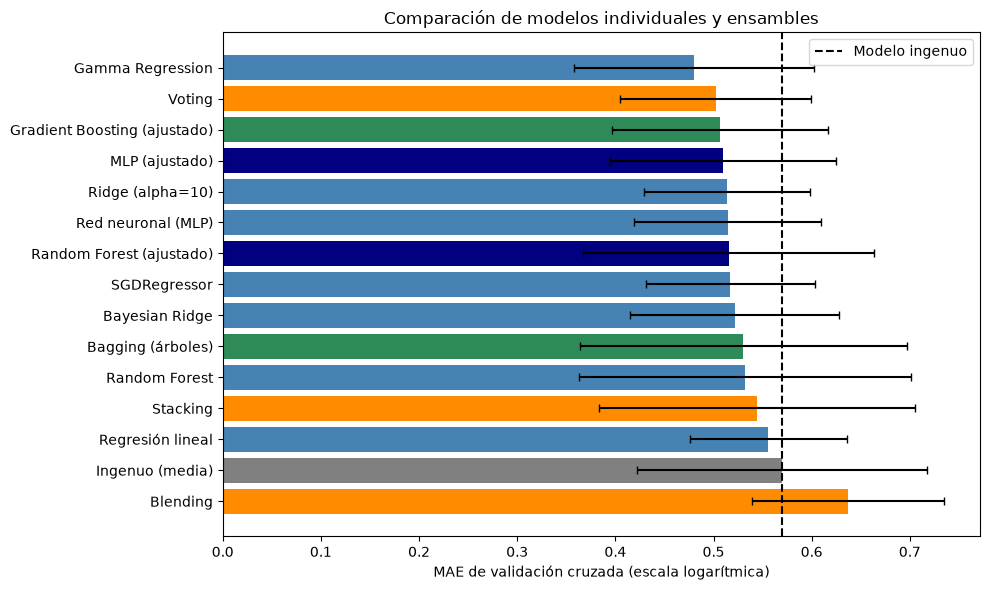

In [6]:
orden = tabla.index.tolist()
colores = {"Referencia": "gray", "Individual": "steelblue", "Individual (bagging)": "steelblue",
           "Individual ajustado (bagging)": "navy", "Individual ajustado": "navy",
           "Ensamble homogéneo": "seagreen", "Ensamble homogéneo (boosting)": "seagreen",
           "Ensamble heterogéneo": "darkorange"}
plt.figure(figsize=(10, 6))
plt.barh(orden[::-1], tabla["MAE val"][::-1], xerr=tabla["MAE val (std)"][::-1], capsize=3,
         color=[colores[tabla.loc[m, "Tipo"]] for m in orden[::-1]])
plt.axvline(tabla.loc["Ingenuo (media)", "MAE val"], color="black", linestyle="--", label="Modelo ingenuo")
plt.xlabel("MAE de validación cruzada (escala logarítmica)")
plt.title("Comparación de modelos individuales y ensambles")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretación de la tabla**

- **Ningún ensamble supera al mejor modelo individual.** El menor MAE de validación cruzada corresponde a la regresión Gamma (0.480), seguida por Voting (0.502) y Gradient Boosting ajustado (0.507). Stacking (0.545) queda apenas por debajo del modelo ingenuo (0.569) y Blending (0.637) queda por encima de él, es decir, resulta peor que predecir siempre la media.
- **Las diferencias entre los modelos de la parte alta de la tabla no son concluyentes.** La desviación estándar del MAE entre particiones es de aproximadamente 0.08 a 0.17, mayor que la distancia entre la regresión Gamma y la mayoría de los modelos. Con 52 observaciones de entrenamiento no es posible afirmar que un modelo sea realmente mejor que otro.
- **Por qué los ensambles no ayudaron.** Combinar modelos funciona cuando los modelos base son razonablemente buenos y cometen errores distintos. Aquí los cuatro modelos combinados pertenecen en su mayoría a la misma familia (lineales y una red pequeña), por lo que sus errores están correlacionados, y ninguno aprende una relación sólida (R² de validación negativo en todos los casos). Además, Stacking y Blending reducen los datos disponibles para entrenar cada etapa; en Blending, el modelo final se ajusta con solo una parte de las 52 observaciones, lo que explica su mal resultado.
- **Los ensambles de árboles muestran sobreajuste.** Gradient Boosting tiene un MAE de entrenamiento de 0.222 contra 0.507 en validación, y Bagging y Random Forest de 0.314 contra 0.53. Son modelos de mayor capacidad que memorizan parte de un conjunto pequeño.
- **Los resultados en el conjunto de prueba reservado (20 observaciones) ordenan distinto los modelos** (los de árboles obtienen el menor MAE, entre 0.36 y 0.37, aunque en validación cruzada son de los peores). Esa discrepancia es otra señal de inestabilidad por el tamaño del conjunto. Por ello la selección se basa en la validación cruzada y la prueba solo se reporta como verificación final, sin usarla para decidir.
- **Cumplimiento de la tolerancia de negocio.** Ningún modelo alcanza el error relativo mediano menor a 30 % propuesto en la fase de baseline: el mejor es 53 % (Gradient Boosting) y el de la regresión Gamma es 58 %, frente a 71 % del modelo ingenuo. Se reduce el error respecto a la referencia, pero no lo suficiente para el uso previsto.
- **Costo computacional.** Todos los modelos se entrenan en menos de un segundo; la búsqueda de hiperparámetros más costosa (Random Forest) tarda cerca de 9 segundos. En este problema el tiempo no es un criterio que diferencie a los modelos tabulares; sí lo es para el detector de imágenes, cuyo entrenamiento es mucho más pesado.

## Selección del modelo final

La actividad pide elegir el modelo final **alineado con los objetivos y las necesidades del negocio**. El objetivo de negocio es identificar de forma automática, a partir de video en tiempo real, a las personas que incumplen el estándar de vestimenta. Esto implica dos criterios que la tabla anterior no cubre:

1. **Detectar y localizar** el objeto en la imagen. Los modelos tabulares no reciben la imagen: únicamente estiman un tamaño a partir de medidas de la cabeza, por lo que no pueden detectar nada por sí mismos.
2. **Velocidad de ejecución:** el sistema debe procesar video con varias personas y deja poco margen para cómputo extra, de modo que combinar varios detectores a cambio de una mejora marginal de recall no es deseable.

**Modelo final elegido: detector Faster R-CNN con umbral de confianza de 0.30** (documentado en `05_Modelo_Final.ipynb`).

Justificación:

- Es el único modelo del proyecto que resuelve la necesidad de negocio, pues recibe la imagen y devuelve la posición del objeto que incumple el estándar.
- Los ensambles tabulares no mejoraron al mejor modelo individual, no alcanzan la tolerancia de error propuesta (30 %) y, aun si lo hicieran, no detectan objetos. Por lo tanto, se descartan como solución y se conservan como evidencia de que la relación geométrica entre la cabeza y el objeto, por sí sola, no basta con los datos actuales. El mejor modelo tabular de referencia es la regresión Gamma.
- Un ensamble de detectores sacrificaría velocidad de procesamiento por una mejora de recall que, con un conjunto de validación de 8 imágenes, no se podría medir de forma confiable.
- El umbral de 0.30 se eligió con la curva FROC como punto de operación: mantiene un recall alto con pocos falsos positivos por imagen.

Resultados del detector en la ejecución documentada (8 imágenes de validación con 16 objetos reales), que deben leerse como preliminares:

| Criterio de acierto | Aciertos | Falsos positivos | Objetos no detectados | Precisión | Recall |
| --- | --- | --- | --- | --- | --- |
| Cualquier solapamiento (IoU > 0, curva FROC) | 13 | 2 | 3 | 0.87 | 0.81 |
| Solapamiento mínimo de 50 % (IoU ≥ 0.5, matriz de confusión) | 7 | 8 | 9 | 0.47 | 0.44 |

La diferencia entre ambas filas se debe al criterio para dar por correcta una detección: con IoU > 0 basta que la caja toque al objeto, mientras que con IoU ≥ 0.5 debe coincidir razonablemente con él. El segundo criterio es el más exigente y realista para evaluar localización; el primero indica si el sistema "ve" el objeto aunque no lo encuadre con precisión.

In [7]:
# Modelo tabular con mejor desempeño de validación (sin contar la referencia ingenua)
mejor = tabla.drop(index="Ingenuo (media)")["MAE val"].idxmin()
modelo_mejor = ajustados[mejor]
print("Mejor modelo tabular por MAE de validación cruzada:", mejor)
print(tabla.loc[mejor, ["MAE val", "MAE val (std)", "R2 val", "Error rel. mediano val", "MAE prueba"]].round(3).to_string())
print("\nReferencia ingenua:", tabla.loc["Ingenuo (media)", ["MAE val", "R2 val", "Error rel. mediano val", "MAE prueba"]].round(3).to_dict())

Mejor modelo tabular por MAE de validación cruzada: Gamma Regression
MAE val                   0.480107
MAE val (std)              0.12263
R2 val                   -0.122238
Error rel. mediano val    0.582593
MAE prueba                0.466466

Referencia ingenua: {'MAE val': 0.5694989251405155, 'R2 val': -0.35667116415359573, 'Error rel. mediano val': 0.7127912286070592, 'MAE prueba': 0.4791925781336802}


## Gráficos del mejor modelo tabular

Se analiza el mejor modelo tabular de la tabla para describir su comportamiento: valores reales contra predichos y residuos (calculados con predicciones de validación cruzada, es decir, hechas por modelos que no vieron esas observaciones) e importancia de las características por permutación sobre el conjunto de entrenamiento.

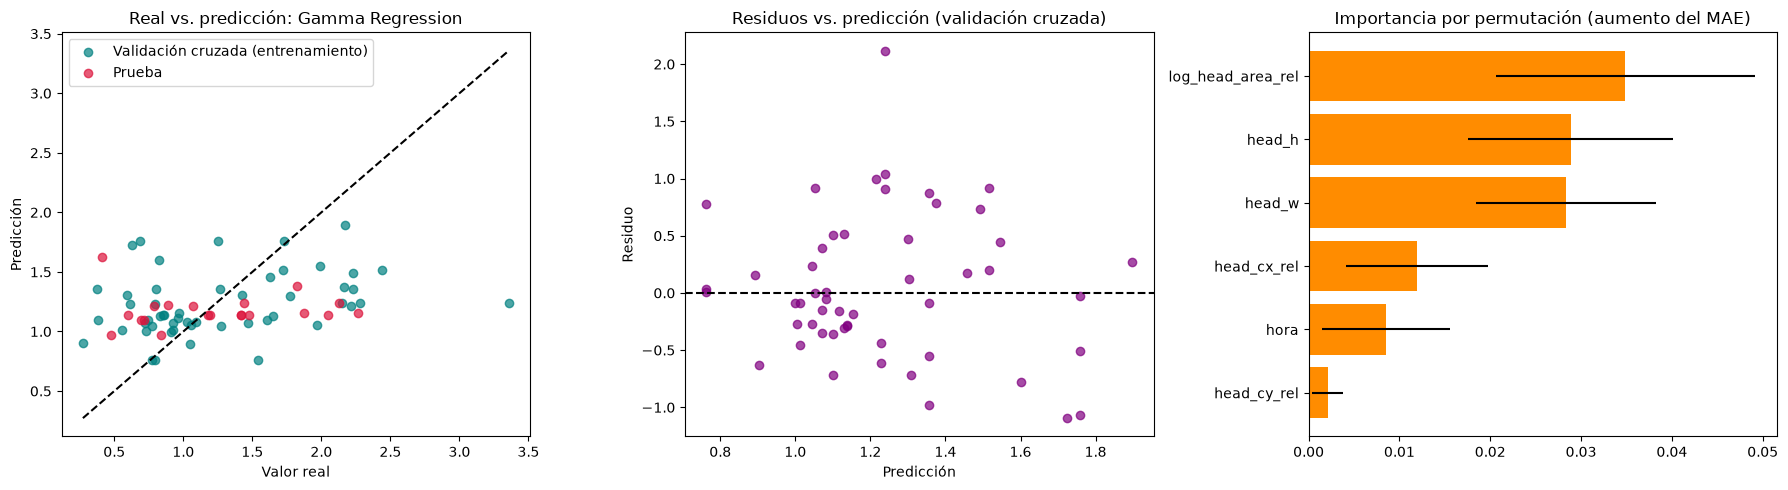

Importancia por permutación (aumento del MAE):
log_head_area_rel    0.0349
head_h               0.0288
head_w               0.0283
head_cx_rel          0.0119
hora                 0.0085
head_cy_rel          0.0021

Correlación entre valor real y residuo: 0.917
Pendiente de la predicción respecto al valor real: 0.125
Rango de predicciones: 0.76 a 1.9 | rango real: 0.27 a 3.36


In [8]:
pred_cv = pred_cv_todos[mejor]
res_cv = y_train - pred_cv
pred_test = modelo_mejor.predict(X_test)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_train, pred_cv, color="teal", alpha=0.7, label="Validación cruzada (entrenamiento)")
axes[0].scatter(y_test, pred_test, color="crimson", alpha=0.7, label="Prueba")
lim = [min(y.min(), pred_cv.min()), max(y.max(), pred_cv.max())]
axes[0].plot(lim, lim, "k--")
axes[0].set_xlabel("Valor real"); axes[0].set_ylabel("Predicción"); axes[0].legend()
axes[0].set_title(f"Real vs. predicción: {mejor}")

axes[1].scatter(pred_cv, res_cv, color="purple", alpha=0.7)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Predicción"); axes[1].set_ylabel("Residuo")
axes[1].set_title("Residuos vs. predicción (validación cruzada)")

perm = permutation_importance(modelo_mejor, X_train, y_train, n_repeats=50, random_state=RANDOM_STATE,
                              scoring="neg_mean_absolute_error")
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
err = pd.Series(perm.importances_std, index=FEATURES)[imp.index]
axes[2].barh(imp.index, imp.values, xerr=err.values, color="darkorange")
axes[2].set_title("Importancia por permutación (aumento del MAE)")
plt.tight_layout()
plt.show()

print("Importancia por permutación (aumento del MAE):")
print(imp.sort_values(ascending=False).round(4).to_string())
print("\nCorrelación entre valor real y residuo:", round(np.corrcoef(y_train, res_cv)[0, 1], 3))
print("Pendiente de la predicción respecto al valor real:", round(np.polyfit(y_train, pred_cv, 1)[0], 3))
print("Rango de predicciones:", round(pred_cv.min(), 2), "a", round(pred_cv.max(), 2),
      "| rango real:", round(y_train.min(), 2), "a", round(y_train.max(), 2))

**Interpretación de los gráficos (regresión Gamma, el mejor modelo tabular)**

- **Real contra predicción:** las predicciones se concentran entre 0.76 y 1.90, mientras que los valores reales van de 0.27 a 3.36. La pendiente de la predicción respecto al valor real es de apenas 0.125 (una pendiente de 1 indicaría un ajuste perfecto). El modelo casi no distingue objetos pequeños de grandes y se aproxima a predecir un valor cercano al promedio.
- **Residuos:** la correlación entre el valor real y el residuo es de 0.92. Esto indica un patrón sistemático: el modelo sobreestima los objetos pequeños y subestima los grandes, no un error aleatorio.
- **Importancia de las características:** las variables de tamaño de la cabeza son las más importantes (`log_head_area_rel` 0.035, `head_h` 0.029 y `head_w` 0.028 de aumento del MAE al permutarlas), seguidas de la posición horizontal de la cabeza (0.012), la hora (0.009) y la posición vertical (0.002). Esto es coherente con la hipótesis de que el tamaño del objeto se relaciona con el de la cabeza, pero las magnitudes son pequeñas y las tres variables de tamaño están correlacionadas entre sí, por lo que comparten la importancia. Dado que el modelo apenas mejora a la referencia, esta evidencia es débil y no debe interpretarse como prueba de que una variable sea inútil o decisiva.

## Conclusiones

- Se construyeron ensambles homogéneos (Bagging y Gradient Boosting con hiperparámetros optimizados) y heterogéneos (Voting, Stacking y Blending con los cuatro mejores modelos individuales de la fase 04) y se compararon, junto con los modelos individuales, en una tabla ordenada por MAE de validación cruzada que incluye RMSE, R², error relativo, MAE en prueba y tiempos de entrenamiento.
- Ningún ensamble mejoró de forma concluyente al mejor modelo individual (regresión Gamma), y Blending resultó peor que la referencia ingenua. Con 52 observaciones de entrenamiento y modelos base de la misma familia, la combinación no aporta diversidad suficiente, y las diferencias entre modelos están dentro de la variabilidad entre particiones.
- Los modelos tabulares no alcanzan la tolerancia de error propuesta (30 %); el mejor llega a 53 %. Se reportan como un experimento preliminar de relación geométrica.
- El modelo final es el detector Faster R-CNN con umbral de 0.30, porque es el único que detecta y localiza el objeto de interés, y porque en un sistema que procesa video no conviene sacrificar velocidad por un ensamble cuya mejora no puede medirse con el conjunto actual.
- El resultado más importante para el proyecto es la limitación de los datos: con más fotografías, un conjunto de validación mayor y ejemplos de personas que sí cumplen el estándar, sería posible evaluar ensambles de detectores (por ejemplo, fusión de cajas) y cuantificar su beneficio de forma confiable.